# Binance daily SVM pilot: step-by-step walkthrough

This notebook exposes the complete approved BTCUSDT pilot one stage at a time. It reuses the repository modules that power `scripts/run_daily_svm_pilot.py`; the notebook does not define an alternative research pipeline.

The stages are: configuration, immutable raw data, internal-gap treatment, feature construction, next-day D0 targets, one transparent rolling training step, the complete rolling SVM pilot, and persisted outputs.

## Methodological boundaries

- Inputs at date `t` are mapped to the next day's outcome: `features(t) -> D0(t + 1)`.
- `D0(t + 1) = high(t + 1) / open(t + 1) - 1`.
- The independent binary thresholds are 2%, 3%, and 4%.
- Internal missing UTC days are forward-filled only in derived data and marked with `is_imputed`; raw files remain unchanged.
- Feature selection and `StandardScaler` are refitted on each training window only. The immediately following observation is transformed but never used for fitting.
- The pilot uses the default parameters of scikit-learn `SVC`. This notebook does not perform grid search, portfolio construction, or backtesting.

In [1]:
from __future__ import annotations

import os
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC


def find_repository_root(start: Path | None = None) -> Path:
    current = (start or Path.cwd()).resolve()
    for candidate in (current, *current.parents):
        if (candidate / 'pyproject.toml').exists() and (candidate / 'src').exists():
            return candidate
    raise FileNotFoundError('Could not locate the repository root.')


REPOSITORY_ROOT = find_repository_root()
os.chdir(REPOSITORY_ROOT)
SOURCE_DIRECTORY = REPOSITORY_ROOT / 'src'
if str(SOURCE_DIRECTORY) not in sys.path:
    sys.path.insert(0, str(SOURCE_DIRECTORY))

from tcc_crypto.daily_feature_selection import (
    DailyFeatureSelector,
    remove_leading_feature_warmup,
)
from tcc_crypto.daily_features import (
    ACTIVE_FEATURES,
    calculate_daily_features,
    load_daily_feature_config,
    load_daily_feature_input,
)
from tcc_crypto.daily_future_high_returns import find_symbol_csv
from tcc_crypto.daily_modeling_dataset import (
    DAY,
    build_daily_modeling_dataset,
    build_next_day_d0_targets,
    load_daily_modeling_dataset_config,
    write_daily_modeling_dataset,
)
from tcc_crypto.daily_svm_pilot import (
    run_default_svc_rolling_pilot,
    write_daily_svm_pilot_results,
)

pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 160)
print(f'Repository root: {REPOSITORY_ROOT}')

Matplotlib is building the font cache; this may take a moment.


Repository root: /Users/marcelapsilverio/projetos/tcc_crypto


## 1. Load and inspect the experiment configuration

The JSON files hold the approved parameters; the Python modules validate and execute them. Keeping parameters outside the implementation makes each run explicit and reproducible.

In [2]:
PILOT_CONFIG_PATH = REPOSITORY_ROOT / 'configs/binance_daily_svm_pilot_dataset.json'
pilot_config = load_daily_modeling_dataset_config(PILOT_CONFIG_PATH)
feature_config = load_daily_feature_config(REPOSITORY_ROOT / pilot_config.feature_config)

configuration_overview = pd.Series(
    {
        'dataset_id': pilot_config.dataset_id,
        'symbol': pilot_config.symbol,
        'warmup_start_utc': pilot_config.warmup_start_utc,
        'sample_start_utc': pilot_config.sample_start_utc,
        'sample_end_utc': pilot_config.sample_end_utc,
        'target_thresholds': pilot_config.target_thresholds,
        'training_window_sizes': pilot_config.training_window_sizes,
        'estimator': pilot_config.estimator,
        'estimator_parameters': pilot_config.estimator_parameters,
        'scaler': pilot_config.scaler,
        'feature_count': len(feature_config.active_features),
        'output_directory': pilot_config.output_directory,
    },
    name='configured_value',
)
display(configuration_overview.to_frame())

,configured_value
dataset_id,btc_daily_svm_pilot_2019H2
symbol,BTCUSDT
warmup_start_utc,2019-06-01 00:00:00+00:00
sample_start_utc,2019-07-01 00:00:00+00:00
sample_end_utc,2019-12-31 00:00:00+00:00
target_thresholds,"(0.02, 0.03, 0.04)"
training_window_sizes,"(60, 75, 90)"
estimator,sklearn.svm.SVC
estimator_parameters,defaults
scaler,sklearn.preprocessing.StandardScaler


## 2. Load the immutable raw daily observations

This stage reads the previously collected Binance CSV. It does not contact Binance and does not modify the raw file. The preview verifies the timestamp range, schema, and OHLC values before any derived treatment.

In [3]:
raw_path = find_symbol_csv(pilot_config.raw_directory, pilot_config.symbol)
raw_values = load_daily_feature_input(raw_path, fill_internal_gaps=False)

raw_overview = pd.Series(
    {
        'source_file': raw_path,
        'row_count': len(raw_values),
        'first_timestamp_utc': raw_values.index.min(),
        'last_timestamp_utc': raw_values.index.max(),
        'duplicate_timestamps': int(raw_values.index.duplicated().sum()),
        'missing_cells': int(raw_values.isna().sum().sum()),
    },
    name='raw_data',
)
display(raw_overview.to_frame())
display(raw_values.head(5))

,raw_data
source_file,data/raw/binance/spot/1d/BTCUSDT/BTCUSDT_1d_20...
row_count,3303
first_timestamp_utc,2017-08-17 00:00:00+00:00
last_timestamp_utc,2026-09-01 00:00:00+00:00
duplicate_timestamps,0
missing_cells,0


,open,high,low,close,quote_asset_volume
open_time_utc,,,,,
2017-08-17 00:00:00+00:00,4261.48,4485.39,4200.74,4285.08,3.454770e+06
2017-08-18 00:00:00+00:00,4285.08,4371.52,3938.77,4108.37,5.086958e+06
2017-08-19 00:00:00+00:00,4108.37,4184.69,3850.00,4139.98,1.549484e+06
2017-08-20 00:00:00+00:00,4120.98,4211.08,4032.62,4086.29,1.930364e+06
2017-08-21 00:00:00+00:00,4069.13,4119.62,3911.79,4016.00,2.797232e+06


## 3. Apply the approved internal-gap treatment

`load_daily_feature_input(..., fill_internal_gaps=True)` calls the repository's gap-treatment layer. It creates only dates bounded by real observations, carries the preceding daily observation forward, and marks synthesized rows. An empty imputed-row preview means that this asset has no internal daily gaps; it is not an error.

In [4]:
aligned_values = load_daily_feature_input(raw_path, fill_internal_gaps=True)
imputed_values = aligned_values.loc[aligned_values['is_imputed']].copy()

gap_overview = pd.Series(
    {
        'raw_rows': len(raw_values),
        'aligned_rows': len(aligned_values),
        'imputed_internal_days': int(aligned_values['is_imputed'].sum()),
        'raw_file_was_modified': False,
    },
    name='gap_treatment',
)
display(gap_overview.to_frame())
display(imputed_values.head(10))

,gap_treatment
raw_rows,3303
aligned_rows,3303
imputed_internal_days,0
raw_file_was_modified,False


,open,high,low,close,quote_asset_volume,is_imputed
open_time_utc,,,,,,


## 4. Calculate features with warm-up history

June 2019 is loaded only to provide earlier observations required by lags and technical indicators. After feature calculation, only leading incomplete rows are removed. The effective pilot sample begins on July 1, 2019.

In [5]:
required_end = pilot_config.sample_end_utc + DAY
calculation_values = aligned_values.loc[
    (aligned_values.index >= pilot_config.warmup_start_utc)
    & (aligned_values.index <= required_end)
].copy()
features_with_warmup = calculate_daily_features(calculation_values)
complete_features = remove_leading_feature_warmup(features_with_warmup)
sample_features = complete_features.loc[
    (complete_features.index >= pilot_config.sample_start_utc)
    & (complete_features.index <= pilot_config.sample_end_utc)
].copy()

feature_overview = pd.Series(
    {
        'calculation_rows_including_warmup': len(calculation_values),
        'leading_rows_removed_after_indicators': len(features_with_warmup) - len(complete_features),
        'pilot_feature_rows': len(sample_features),
        'first_pilot_feature_date': sample_features.index.min(),
        'last_pilot_feature_date': sample_features.index.max(),
        'feature_count': sample_features.shape[1],
        'missing_pilot_feature_cells': int(sample_features.isna().sum().sum()),
    },
    name='feature_construction',
)
display(feature_overview.to_frame())
display(sample_features.head(5))

,feature_construction
calculation_rows_including_warmup,215
leading_rows_removed_after_indicators,14
pilot_feature_rows,184
first_pilot_feature_date,2019-07-01 00:00:00+00:00
last_pilot_feature_date,2019-12-31 00:00:00+00:00
feature_count,22
missing_pilot_feature_cells,0


,r1,r2,r3,r4,r5,r6,r7,r8,r9,r10,r11,r12,r13,r14,r15,momentum_10,rsi_14,parabolic_sar,atr_14,true_range,chaikin_ad,obv
open_time_utc,,,,,,,,,,,,,,,,,,,,,,
2019-07-01 00:00:00+00:00,-0.021340,-0.092259,-0.040946,0.090294,0.038690,-0.053568,-0.095032,-0.004220,0.022994,0.002775,0.096674,-0.078962,-0.100406,-0.078093,-0.031115,465.07,52.859527,7444.58,943.361958,1252.28,2.364909e+09,4.148481e+09
2019-07-02 00:00:00+00:00,0.020303,-0.021340,-0.092259,-0.040946,0.029111,0.007769,-0.084490,-0.125954,0.038690,0.022994,0.002775,-0.088295,-0.078962,-0.100406,-0.078093,113.35,54.309046,7444.58,962.532532,1211.75,3.314663e+09,5.276835e+09
2019-07-03 00:00:00+00:00,0.096388,0.020303,-0.021340,-0.092259,0.100528,0.121030,0.099688,0.007429,0.029111,0.038690,0.022994,-0.000363,-0.088295,-0.078962,-0.100406,1033.93,60.838063,7444.58,975.983780,1150.85,4.313471e+09,6.374640e+09
2019-07-04 00:00:00+00:00,-0.068843,0.096388,0.020303,-0.021340,0.005013,0.101204,0.121706,0.100364,0.100528,0.029111,0.038690,-0.077011,-0.000363,-0.088295,-0.078962,89.08,54.739367,7444.58,973.770653,945.00,3.686527e+09,5.598821e+09
2019-07-05 00:00:00+00:00,-0.015820,-0.068843,0.096388,0.020303,0.023161,-0.045682,0.050510,0.071012,0.005013,0.100528,0.029111,-0.031835,-0.077011,-0.000363,-0.088295,-850.13,53.468122,7444.58,947.814892,610.39,3.383771e+09,4.892967e+09


## 5. Construct and inspect the next-day D0 targets

For every feature row at `t`, the target builder reads the open and high from `t + 1`. The return is converted independently into three labels. The displayed rows make this alignment auditable.

In [6]:
targets = build_next_day_d0_targets(
    calculation_values,
    sample_features.index,
    thresholds=pilot_config.target_thresholds,
)
target_columns = ['target_2pct', 'target_3pct', 'target_4pct']
display(
    targets.loc[
        :,
        ['target_date_utc', 'next_day_open', 'next_day_high', 'next_day_d0', *target_columns],
    ].head(10)
)

,target_date_utc,next_day_open,next_day_high,next_day_d0,target_2pct,target_3pct,target_4pct
feature_date_utc,,,,,,,
2019-07-01 00:00:00+00:00,2019-07-02 00:00:00+00:00,10624.90,10938.75,0.029539,1,0,0
2019-07-02 00:00:00+00:00,2019-07-03 00:00:00+00:00,10844.98,11991.89,0.105755,1,1,1
2019-07-03 00:00:00+00:00,2019-07-04 00:00:00+00:00,11940.00,12000.00,0.005025,0,0,0
2019-07-04 00:00:00+00:00,2019-07-05 00:00:00+00:00,11145.67,11406.83,0.023432,1,0,0
2019-07-05 00:00:00+00:00,2019-07-06 00:00:00+00:00,10982.41,11665.00,0.062153,1,1,1
2019-07-06 00:00:00+00:00,2019-07-07 00:00:00+00:00,11256.45,11538.00,0.025012,1,0,0
2019-07-07 00:00:00+00:00,2019-07-08 00:00:00+00:00,11410.00,12338.03,0.081335,1,1,1
2019-07-08 00:00:00+00:00,2019-07-09 00:00:00+00:00,12238.60,12794.73,0.045441,1,1,1
2019-07-09 00:00:00+00:00,2019-07-10 00:00:00+00:00,12548.51,13147.08,0.047700,1,1,1


,negative,positive,positive_rate
target_2pct,117,67,0.364130
target_3pct,138,46,0.250000
target_4pct,151,33,0.179348


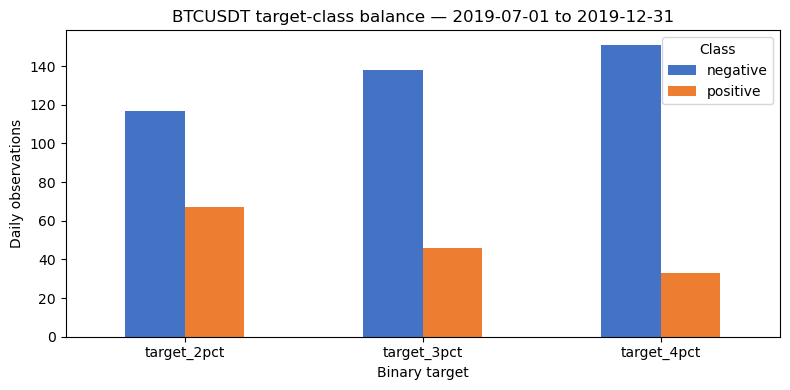

In [7]:
target_balance = pd.DataFrame(
    {
        'negative': [(targets[column] == 0).sum() for column in target_columns],
        'positive': [(targets[column] == 1).sum() for column in target_columns],
    },
    index=target_columns,
)
target_balance['positive_rate'] = (
    target_balance['positive'] / target_balance[['negative', 'positive']].sum(axis=1)
)
display(target_balance)

ax = target_balance[['negative', 'positive']].plot.bar(
    figsize=(8, 4),
    color=['#4472C4', '#ED7D31'],
)
ax.set_title('BTCUSDT target-class balance — 2019-07-01 to 2019-12-31')
ax.set_xlabel('Binary target')
ax.set_ylabel('Daily observations')
ax.legend(title='Class')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 6. Assemble the official modeling dataset

The prior cells exposed the internals for inspection. This cell now calls `build_daily_modeling_dataset`, the same orchestration function used by the executable script, and verifies the resulting modeling table.

In [8]:
modeling_dataset = build_daily_modeling_dataset(pilot_config)

dataset_overview = pd.Series(
    {
        'rows': len(modeling_dataset),
        'columns': modeling_dataset.shape[1],
        'feature_columns': len(ACTIVE_FEATURES),
        'feature_imputed_rows': int(modeling_dataset['feature_is_imputed'].sum()),
        'target_imputed_rows': int(modeling_dataset['target_is_imputed'].fillna(False).sum()),
        'first_date': modeling_dataset.index.min(),
        'last_date': modeling_dataset.index.max(),
    },
    name='modeling_dataset',
)
display(dataset_overview.to_frame())
display(modeling_dataset.head(5))

,modeling_dataset
rows,184
columns,32
feature_columns,22
feature_imputed_rows,0
target_imputed_rows,0
first_date,2019-07-01 00:00:00+00:00
last_date,2019-12-31 00:00:00+00:00


,symbol,feature_is_imputed,r1,r2,r3,r4,r5,r6,r7,r8,r9,r10,r11,r12,r13,r14,r15,momentum_10,rsi_14,parabolic_sar,atr_14,true_range,chaikin_ad,obv,target_date_utc,next_day_open,next_day_high,next_day_d0,target_is_imputed,target_2pct,target_3pct,target_4pct
feature_date_utc,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2019-07-01 00:00:00+00:00,BTCUSDT,False,-0.021340,-0.092259,-0.040946,0.090294,0.038690,-0.053568,-0.095032,-0.004220,0.022994,0.002775,0.096674,-0.078962,-0.100406,-0.078093,-0.031115,465.07,52.859527,7444.58,943.361958,1252.28,2.364909e+09,4.148481e+09,2019-07-02 00:00:00+00:00,10624.90,10938.75,0.029539,False,1,0,0
2019-07-02 00:00:00+00:00,BTCUSDT,False,0.020303,-0.021340,-0.092259,-0.040946,0.029111,0.007769,-0.084490,-0.125954,0.038690,0.022994,0.002775,-0.088295,-0.078962,-0.100406,-0.078093,113.35,54.309046,7444.58,962.532532,1211.75,3.314663e+09,5.276835e+09,2019-07-03 00:00:00+00:00,10844.98,11991.89,0.105755,False,1,1,1
2019-07-03 00:00:00+00:00,BTCUSDT,False,0.096388,0.020303,-0.021340,-0.092259,0.100528,0.121030,0.099688,0.007429,0.029111,0.038690,0.022994,-0.000363,-0.088295,-0.078962,-0.100406,1033.93,60.838063,7444.58,975.983780,1150.85,4.313471e+09,6.374640e+09,2019-07-04 00:00:00+00:00,11940.00,12000.00,0.005025,False,0,0,0
2019-07-04 00:00:00+00:00,BTCUSDT,False,-0.068843,0.096388,0.020303,-0.021340,0.005013,0.101204,0.121706,0.100364,0.100528,0.029111,0.038690,-0.077011,-0.000363,-0.088295,-0.078962,89.08,54.739367,7444.58,973.770653,945.00,3.686527e+09,5.598821e+09,2019-07-05 00:00:00+00:00,11145.67,11406.83,0.023432,False,1,0,0
2019-07-05 00:00:00+00:00,BTCUSDT,False,-0.015820,-0.068843,0.096388,0.020303,0.023161,-0.045682,0.050510,0.071012,0.005013,0.100528,0.029111,-0.031835,-0.077011,-0.000363,-0.088295,-850.13,53.468122,7444.58,947.814892,610.39,3.383771e+09,4.892967e+09,2019-07-06 00:00:00+00:00,10982.41,11665.00,0.062153,False,1,1,1


## 7. Inspect one rolling SVM training step

Before running every combination, this section reproduces one step transparently: the first 60 observations train the 2% target model, and observation 61 is the out-of-sample prediction row. This is an educational view of the same operations implemented by `run_default_svc_rolling_pilot`.

In [9]:
example_target = 'target_2pct'
example_window_size = 60
feature_matrix = modeling_dataset.loc[:, ACTIVE_FEATURES].astype('float64')
labels = modeling_dataset[example_target].astype('int64')

training_features = feature_matrix.iloc[:example_window_size]
prediction_features = feature_matrix.iloc[example_window_size:example_window_size + 1]
training_labels = labels.iloc[:example_window_size]
actual_label = int(labels.iloc[example_window_size])

window_overview = pd.Series(
    {
        'target': example_target,
        'window_size': example_window_size,
        'training_start_utc': training_features.index[0],
        'training_end_utc': training_features.index[-1],
        'prediction_time_utc': prediction_features.index[0],
        'training_negative': int((training_labels == 0).sum()),
        'training_positive': int((training_labels == 1).sum()),
        'actual_out_of_sample_label': actual_label,
    },
    name='first_rolling_step',
)
display(window_overview.to_frame())

,first_rolling_step
target,target_2pct
window_size,60
training_start_utc,2019-07-01 00:00:00+00:00
training_end_utc,2019-08-29 00:00:00+00:00
prediction_time_utc,2019-08-30 00:00:00+00:00
training_negative,28
training_positive,32
actual_out_of_sample_label,0


In [10]:
selector = DailyFeatureSelector(
    variance_threshold=feature_config.feature_selection.variance_threshold,
    correlation_threshold=feature_config.feature_selection.correlation_threshold,
)
selected_training = selector.fit_transform(training_features)
selected_prediction = selector.transform(prediction_features)

selection_overview = pd.Series(
    {
        'input_feature_count': training_features.shape[1],
        'selected_feature_count': len(selector.selected_features_),
        'selected_features': ', '.join(selector.selected_features_),
        'fit_rows': len(selected_training),
        'transformed_future_rows': len(selected_prediction),
    },
    name='training-only feature selection',
)
display(selection_overview.to_frame())

,training-only feature selection
input_feature_count,22
selected_feature_count,5
selected_features,"momentum_10, rsi_14, atr_14, true_range, obv"
fit_rows,60
transformed_future_rows,1


In [11]:
scaler = StandardScaler()
scaled_training = scaler.fit_transform(selected_training)
scaled_prediction = scaler.transform(selected_prediction)
scaled_training_frame = pd.DataFrame(
    scaled_training,
    index=selected_training.index,
    columns=selected_training.columns,
)

scaling_diagnostics = pd.DataFrame(
    {
        'training_mean_after_scaling': scaled_training_frame.mean(),
        'training_std_after_scaling': scaled_training_frame.std(ddof=0),
        'prediction_scaled_value': scaled_prediction[0],
    }
)
display(scaling_diagnostics.head(10))
print('The scaler was fitted on training rows only; the prediction row was only transformed.')

,training_mean_after_scaling,training_std_after_scaling,prediction_scaled_value
momentum_10,-3.330669e-17,1.0,-0.823906
rsi_14,6.476301e-16,1.0,-1.542904
atr_14,3.330669e-17,1.0,-1.524388
true_range,-3.885781e-17,1.0,-1.071464
obv,1.258253e-16,1.0,-0.004426


The scaler was fitted on training rows only; the prediction row was only transformed.


In [12]:
example_estimator = SVC()
example_estimator.fit(scaled_training, training_labels)
example_prediction = int(example_estimator.predict(scaled_prediction)[0])
example_score = float(example_estimator.decision_function(scaled_prediction)[0])

example_result = pd.Series(
    {
        'estimator': type(example_estimator).__name__,
        'kernel': example_estimator.kernel,
        'C': example_estimator.C,
        'gamma': example_estimator.gamma,
        'prediction': example_prediction,
        'actual': actual_label,
        'correct': example_prediction == actual_label,
        'decision_score': example_score,
    },
    name='one out-of-sample prediction',
)
display(example_result.to_frame())

,one out-of-sample prediction
estimator,SVC
kernel,rbf
C,1.0
gamma,scale
prediction,1
actual,0
correct,False
decision_score,0.761031


## 8. Run the complete rolling default-SVC pilot

The repository function repeats the demonstrated sequence for every prediction date, each target, and each 60-, 75-, and 90-day window. Rows whose training window contains only one class are recorded explicitly and do not receive an invented prediction.

In [13]:
pilot_result = run_default_svc_rolling_pilot(
    modeling_dataset,
    selection_config=feature_config.feature_selection,
)

run_overview = pd.Series(
    {
        'rolling_result_rows': len(pilot_result.predictions),
        'successful_predictions': int((pilot_result.predictions['status'] == 'ok').sum()),
        'single_class_windows': int((pilot_result.predictions['status'] == 'single_class_training').sum()),
        'summary_rows': len(pilot_result.summary),
    },
    name='complete_pilot',
)
display(run_overview.to_frame())
display(pilot_result.predictions.head(10))

,complete_pilot
rolling_result_rows,981
successful_predictions,981
single_class_windows,0
summary_rows,9


,target,window_size,training_start_utc,training_end_utc,prediction_time_utc,actual,training_negative,training_positive,selected_feature_count,selected_features,status,prediction,decision_score,in_sample_accuracy,in_sample_precision,in_sample_recall,in_sample_f1
0,target_2pct,60,2019-07-01 00:00:00+00:00,2019-08-29 00:00:00+00:00,2019-08-30 00:00:00+00:00,0,28,32,5,momentum_10|rsi_14|atr_14|true_range|obv,ok,1,0.761031,0.750000,0.707317,0.906250,0.794521
1,target_2pct,60,2019-07-02 00:00:00+00:00,2019-08-30 00:00:00+00:00,2019-08-31 00:00:00+00:00,1,29,31,5,momentum_10|rsi_14|atr_14|true_range|obv,ok,0,-0.191913,0.733333,0.692308,0.870968,0.771429
2,target_2pct,60,2019-07-03 00:00:00+00:00,2019-08-31 00:00:00+00:00,2019-09-01 00:00:00+00:00,1,29,31,5,momentum_10|rsi_14|atr_14|true_range|obv,ok,1,0.012458,0.766667,0.717949,0.903226,0.800000
3,target_2pct,60,2019-07-04 00:00:00+00:00,2019-09-01 00:00:00+00:00,2019-09-02 00:00:00+00:00,1,28,32,5,momentum_10|rsi_14|atr_14|true_range|obv,ok,0,-1.097992,0.750000,0.707317,0.906250,0.794521
4,target_2pct,60,2019-07-05 00:00:00+00:00,2019-09-02 00:00:00+00:00,2019-09-03 00:00:00+00:00,0,28,32,5,momentum_10|rsi_14|atr_14|true_range|obv,ok,0,-0.952067,0.800000,0.794118,0.843750,0.818182
5,target_2pct,60,2019-07-06 00:00:00+00:00,2019-09-03 00:00:00+00:00,2019-09-04 00:00:00+00:00,1,29,31,5,momentum_10|rsi_14|atr_14|true_range|obv,ok,0,-0.639151,0.800000,0.827586,0.774194,0.800000
6,target_2pct,60,2019-07-07 00:00:00+00:00,2019-09-04 00:00:00+00:00,2019-09-05 00:00:00+00:00,1,29,31,4,momentum_10|atr_14|true_range|obv,ok,0,-0.034274,0.733333,0.777778,0.677419,0.724138
7,target_2pct,60,2019-07-08 00:00:00+00:00,2019-09-05 00:00:00+00:00,2019-09-06 00:00:00+00:00,1,29,31,4,momentum_10|atr_14|true_range|obv,ok,1,0.850361,0.733333,0.758621,0.709677,0.733333
8,target_2pct,60,2019-07-09 00:00:00+00:00,2019-09-06 00:00:00+00:00,2019-09-07 00:00:00+00:00,0,29,31,4,momentum_10|atr_14|true_range|obv,ok,1,0.860506,0.750000,0.766667,0.741935,0.754098
9,target_2pct,60,2019-07-10 00:00:00+00:00,2019-09-07 00:00:00+00:00,2019-09-08 00:00:00+00:00,0,30,30,4,momentum_10|atr_14|true_range|obv,ok,1,0.947083,0.716667,0.709677,0.733333,0.721311


## 9. Inspect in-sample diagnostics and out-of-sample metrics

In-sample metrics describe the fitted rolling windows. The `out_of_sample_*` columns aggregate the one-step-ahead predictions and are the appropriate pilot view of behavior on unseen rows. These diagnostics validate the pipeline; they do not select final hyperparameters.

,target,window_size,prediction_count,successful_prediction_count,single_class_count,out_of_sample_accuracy,out_of_sample_precision,out_of_sample_recall,out_of_sample_f1,true_negative,false_positive,false_negative,true_positive,mean_in_sample_accuracy,mean_in_sample_precision,mean_in_sample_recall,mean_in_sample_f1
0,target_2pct,60,124,124,0,0.693548,0.400000,0.171429,0.240000,80,9,29,6,0.775269,0.880029,0.362214,0.467263
1,target_2pct,75,109,109,0,0.743119,0.500000,0.142857,0.222222,77,4,24,4,0.775413,0.922383,0.349852,0.475457
2,target_2pct,90,94,94,0,0.734043,0.571429,0.153846,0.242424,65,3,22,4,0.769622,0.909231,0.341169,0.468492
3,target_3pct,60,124,124,0,0.798387,0.333333,0.041667,0.074074,98,2,23,1,0.801747,0.762903,0.119365,0.202983
4,target_3pct,75,109,109,0,0.807339,0.333333,0.050000,0.086957,87,2,19,1,0.804281,0.860550,0.107086,0.188255
5,target_3pct,90,94,94,0,0.776596,0.333333,0.050000,0.086957,72,2,19,1,0.804019,0.860372,0.093558,0.165869
6,target_4pct,60,124,124,0,0.879032,0.000000,0.000000,0.000000,109,0,15,0,0.877823,0.750000,0.164778,0.264774
7,target_4pct,75,109,109,0,0.880734,0.000000,0.000000,0.000000,96,0,13,0,0.880856,0.889908,0.166743,0.275966
8,target_4pct,90,94,94,0,0.861702,0.000000,0.000000,0.000000,81,0,13,0,0.879669,0.904255,0.145121,0.246424


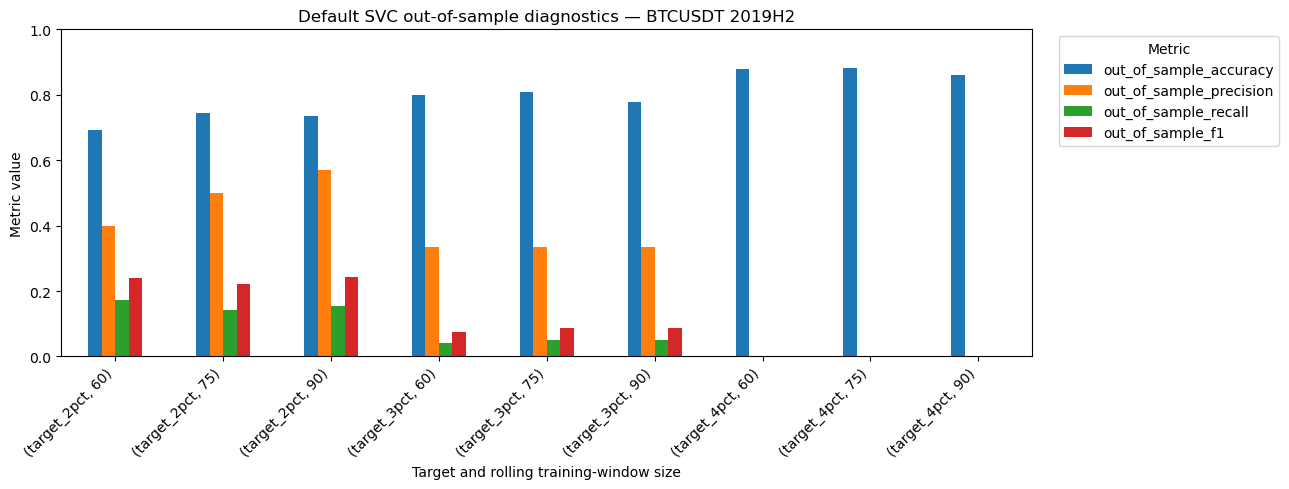

In [14]:
display(pilot_result.summary)

metric_columns = [
    'out_of_sample_accuracy',
    'out_of_sample_precision',
    'out_of_sample_recall',
    'out_of_sample_f1',
]
metric_plot = pilot_result.summary.set_index(['target', 'window_size'])[metric_columns]
ax = metric_plot.plot.bar(figsize=(13, 5))
ax.set_title('Default SVC out-of-sample diagnostics — BTCUSDT 2019H2')
ax.set_xlabel('Target and rolling training-window size')
ax.set_ylabel('Metric value')
ax.set_ylim(0, 1)
ax.legend(title='Metric', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

## 10. Persist the same artifacts as the executable pipeline

The final step writes the derived modeling dataset, rolling predictions, metric summary, and reproducibility metadata to the configured output directory. These are generated artifacts and remain outside Git.

In [15]:
dataset_paths = write_daily_modeling_dataset(pilot_config, modeling_dataset)
result_paths = write_daily_svm_pilot_results(pilot_config, pilot_result)

written_artifacts = pd.DataFrame(
    {
        'artifact': [
            'modeling dataset',
            'dataset metadata',
            'rolling predictions',
            'metrics summary',
            'run metadata',
        ],
        'path': [str(path) for path in (*dataset_paths, *result_paths)],
    }
)
display(written_artifacts)

,artifact,path
0,modeling dataset,outputs/btc_daily_svm_pilot_2019H2/btc_daily_s...
1,dataset metadata,outputs/btc_daily_svm_pilot_2019H2/btc_daily_s...
2,rolling predictions,outputs/btc_daily_svm_pilot_2019H2/default_svc...
3,metrics summary,outputs/btc_daily_svm_pilot_2019H2/default_svc...
4,run metadata,outputs/btc_daily_svm_pilot_2019H2/default_svc...


## Interpretation limits and next step

This notebook demonstrates the approved default-SVC pilot and its temporal safeguards. It does not establish the final classifier, because the time-aware validation procedure, grid-search metric, and SVM hyperparameter search space still require approval. It also does not yet expand the experiment to every eligible cryptocurrency or construct portfolios.